# RetailPulse — 03 · Exploratory Data Analysis

**Phase 5 deliverable** · builds on the cleaned data (Phase 3) and the SQL findings (Phase 4)

---

## What this notebook is for

Phases 1–4 established *what the data is* and *that the numbers are right*.
This notebook asks **what the business should do about it**.

It is deliberately not a re-run of earlier work. Phase 1 already charted
missing values, monthly order counts, the delivery-time histogram, order
status, the review distribution and orders-per-customer. None of those are
repeated here.

Instead every chart below answers a business question that Phases 1–4 raised
but did not resolve:

| Section | The question |
|---|---|
| A · Executive | Is growth real, and where does revenue actually come from? |
| B · Customer | Is there anything worth retaining, given a 3% repeat rate? |
| C · Product | Which categories carry the business, and which are dying? |
| D · Seller | Which sellers should management actually call? |
| E · Delivery | Where do deliveries fail, and are the promises honest? |
| F · Satisfaction | What drives a 1-star review? |

### Rules carried in from earlier phases

These are not re-derived here; they were established and validated already.

- **Revenue** = `SUM(order_items.price)`, excluding freight. No profit or
  margin is ever computed — the dataset has no cost column.
- **Customers** are counted on `customer_unique_id` (96,096 people), never
  `customer_id` (99,441 order records).
- **Trends** use the stable window **2017-01 → 2018-08**. The edge months hold
  4, 1, 16 and 4 orders, and November 2016 is absent entirely.
- **Delivery metrics** use the 96,476 orders with a real delivery date, not
  the 96,478 marked `delivered`.
- **Canceled and unavailable orders** are excluded from revenue but never
  deleted — they are reported separately as lost demand.
- Correlation is labelled as correlation. Nothing here claims causation.

### Independent validation

Section G re-checks the headline numbers against **MySQL**, which computed
them from a separate engine over a separate copy of the data. Pandas and SQL
agreeing is evidence; pandas alone is just one implementation.

## 0 · Setup

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CLEANED = PROJECT_ROOT / "dataset" / "cleaned"
CHARTS  = PROJECT_ROOT / "reports" / "eda_charts"
CHARTS.mkdir(parents=True, exist_ok=True)

assert CLEANED.exists(), f"Cleaned data not found at {CLEANED}"
print("cleaned :", CLEANED)
print("charts  :", CHARTS)
print("pandas", pd.__version__)

cleaned : /Users/manish/Desktop/RetailPulse/dataset/cleaned
charts  : /Users/manish/Desktop/RetailPulse/reports/eda_charts
pandas 3.1.1


### Chart style

One consistent style, defined once. Three choices worth stating:

- **A validated colour palette.** The three hues used here were checked with a
  colour-vision-deficiency simulator: the worst adjacent pair separates by
  ΔE 23.1 for protanopia, well clear of the ΔE 8 threshold. Colour is never
  the only thing distinguishing two series — direct labels or position always
  carry the same information.
- **Light background, orange accent.** The Phase 6 dashboard theme is dark
  charcoal, but notebooks get read on white — on GitHub, in a PDF. The accent
  `#eb6834` is shared with that theme so the project still looks like one system.
- **One colour per chart unless colour means something.** Most charts below
  show a single series, so colour carries no information and no legend is
  drawn — the title names the series. Red is reserved for flagging problems
  and never used as a data colour.

In [2]:
# --- validated palette (see Phase 1 notebook for the CVD check) -------------
INK      = "#1a1a19"   # primary text
INK_SOFT = "#52514e"   # secondary text, axis labels
ACCENT   = "#eb6834"   # project orange — the default single-series colour
BLUE     = "#2a78d6"   # second series only
AQUA     = "#1baf7a"   # third series only
CRITICAL = "#e34948"   # reserved for flagging problems, never a data series
GOOD     = "#1baf7a"
GRID     = "#e4e3df"
SURFACE  = "#ffffff"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_SOFT, "axes.titlecolor": INK,
    "axes.titlesize": 12.5, "axes.titleweight": "bold", "axes.titlepad": 12,
    "axes.labelsize": 10, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK_SOFT, "ytick.color": INK_SOFT,
    "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "legend.fontsize": 9,
    "figure.dpi": 110, "savefig.bbox": "tight", "savefig.dpi": 140,
    "font.size": 10,
})

def tidy(ax, xgrid=False, ygrid=True):
    """Remove chart junk: no top/right spines, grid on one axis only."""
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.spines["left"].set_color(GRID); ax.spines["bottom"].set_color(GRID)
    ax.xaxis.grid(xgrid); ax.yaxis.grid(ygrid)
    return ax

def money(ax, axis="y", millions=False):
    f = (lambda v, _: f"{v/1e6:,.1f}M") if millions else (lambda v, _: f"{v:,.0f}")
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(mticker.FuncFormatter(f))
    return ax

SAVED = []
def save(fig, name):
    """Save a chart and record it, so the notebook can report what it produced."""
    path = CHARTS / f"{name}.png"
    fig.savefig(path)
    SAVED.append(name)
    print(f"   saved -> reports/eda_charts/{name}.png")

print("chart style configured")

chart style configured


### Load the cleaned data

Reading the Phase 3 output, not the raw files. The cleaning decisions
(flags, derived columns, English category names) are already baked in.

In [3]:
orders    = pd.read_csv(CLEANED / "orders_clean.csv", low_memory=False)
items     = pd.read_csv(CLEANED / "order_items_clean.csv", low_memory=False)
reviews   = pd.read_csv(CLEANED / "order_reviews_clean.csv", low_memory=False)
payments  = pd.read_csv(CLEANED / "order_payments_clean.csv", low_memory=False)
sellers   = pd.read_csv(CLEANED / "sellers_clean.csv", dtype=str)

# Booleans round-trip through CSV as the strings 'True'/'False'.
BOOL_COLS = ["is_delivered", "revenue_eligible", "has_items", "has_review",
             "in_stable_window", "delivery_measurable",
             "has_date_anomaly", "has_delivery_anomaly"]
for c in BOOL_COLS:
    if c in orders.columns:
        orders[c] = orders[c].map({"True": True, "False": False,
                                   True: True, False: False}).astype(bool)

# is_late is the exception: it is NULL for the 2,965 orders that were never
# delivered. Mapping it to bool would turn those into False and silently
# count an undelivered order as on-time. Stored as float (1.0/0.0/NaN) so
# .mean() skips the nulls and gives a rate over the 96,476 measurable orders.
orders["is_late"] = orders.is_late.map({"True": 1.0, "False": 0.0,
                                        True: 1.0, False: 0.0}).astype(float)
items["revenue_eligible"] = items.revenue_eligible.map(
    {"True": True, "False": False, True: True, False: False})

orders["order_purchase_timestamp"] = pd.to_datetime(orders.order_purchase_timestamp)
orders["order_date"] = pd.to_datetime(orders.order_date)

# Convenience slices used throughout
ELIG        = orders[orders.revenue_eligible]                    # revenue-eligible orders
ELIG_ITEMS  = items[items.revenue_eligible]                      # revenue-eligible item lines
STABLE      = orders[orders.in_stable_window]                    # 2017-01 .. 2018-08
DELIVERED   = orders[orders.delivery_measurable]                 # has a real delivery date

print(f"orders   {len(orders):>8,}   eligible {len(ELIG):>8,}   stable {len(STABLE):>8,}")
print(f"items    {len(items):>8,}   eligible {len(ELIG_ITEMS):>8,}")
print(f"reviews  {len(reviews):>8,}   delivered-measurable {len(DELIVERED):>8,}")
print(f"people   {orders.customer_unique_id.nunique():>8,}")

orders     99,441   eligible   98,207   stable   99,092
items     112,650   eligible  112,101
reviews    99,224   delivered-measurable   96,476
people     96,096


---
## A · Executive Business Analysis

### A1. Is growth real, and is it slowing?

In [4]:
monthly = (ELIG[ELIG.in_stable_window]
           .groupby("order_month")
           .agg(orders=("order_id", "nunique"),
                revenue=("order_revenue", "sum"),
                customers=("customer_unique_id", "nunique"))
           .reset_index())
monthly["aov"] = monthly.revenue / monthly.orders
monthly["mom_pct"] = monthly.revenue.pct_change() * 100
monthly["ma3"] = monthly.revenue.rolling(3).mean()

print(f"Stable window: {monthly.order_month.min()} .. {monthly.order_month.max()} "
      f"({len(monthly)} months)")
print(f"Total eligible revenue in window: {monthly.revenue.sum():,.2f} BRL")
display(monthly.tail(6).round(2))

Stable window: 2017-01 .. 2018-08 (20 months)
Total eligible revenue in window: 13,449,529.68 BRL


,order_month,orders,revenue,customers,aov,mom_pct,ma3
14,2018-03,7168,"981,051.06",7077,136.87,17.09,"921,467.59"
15,2018-04,6919,"993,592.98",6863,143.60,1.28,"937,513.16"
16,2018-05,6833,"992,871.75",6775,145.31,-0.07,"989,171.93"
17,2018-06,6145,"863,265.53",6106,140.48,-13.05,"949,910.09"
18,2018-07,6233,"878,044.27",6172,140.87,1.71,"911,393.85"
19,2018-08,6421,"848,860.10",6380,132.20,-3.32,"863,389.97"


   saved -> reports/eda_charts/A1_revenue_trend_and_mom_growth.png


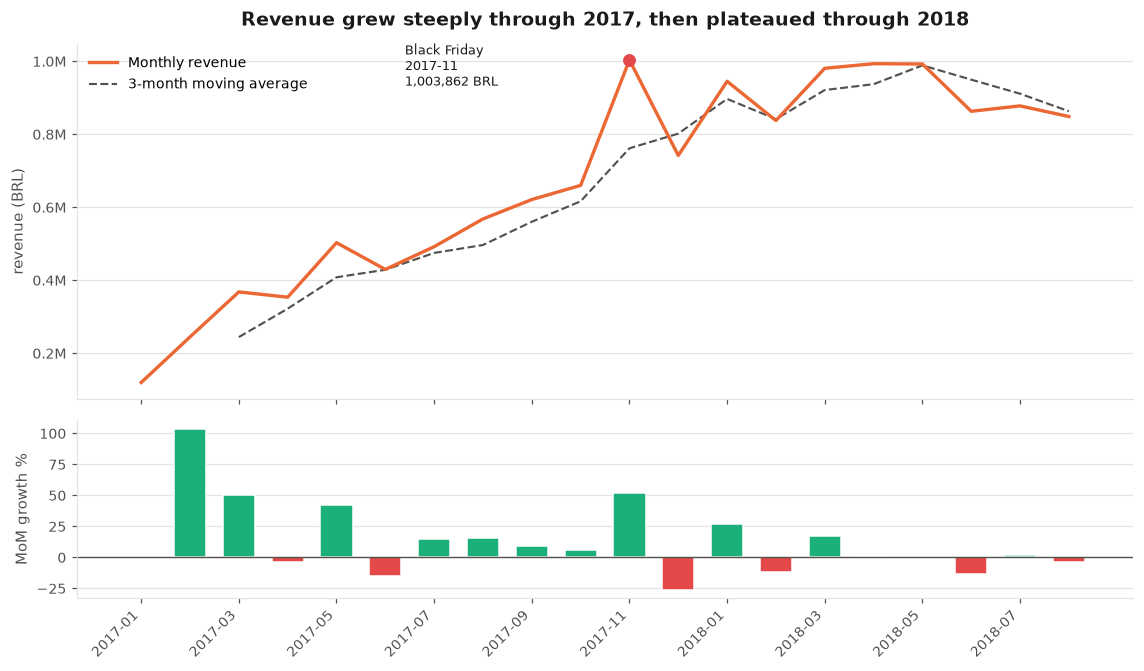

Months with negative MoM growth: 7 of 19
Mean MoM growth 2017: +22.7%
Mean MoM growth 2018: +2.5%


In [5]:
# Two stacked panels sharing an x-axis, NOT a dual-axis chart. Two y-scales on
# one chart make unrelated series look correlated and invite false readings;
# small multiples keep each scale honest.
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10.5, 6.2), sharex=True,
                               gridspec_kw={"height_ratios": [2, 1]})

x = np.arange(len(monthly))
ax1.plot(x, monthly.revenue, color=ACCENT, linewidth=2.2, zorder=3, label="Monthly revenue")
ax1.plot(x, monthly.ma3, color=INK_SOFT, linewidth=1.4, linestyle="--",
         zorder=2, label="3-month moving average")
peak = int(monthly.revenue.idxmax())
ax1.scatter([peak], [monthly.revenue.iloc[peak]], s=55, color=CRITICAL, zorder=5)
ax1.annotate(f"Black Friday\n{monthly.order_month.iloc[peak]}\n{monthly.revenue.iloc[peak]:,.0f} BRL",
             xy=(peak, monthly.revenue.iloc[peak]), xytext=(peak - 4.6, monthly.revenue.iloc[peak] * 0.93),
             fontsize=8.5, color=INK, ha="left")
ax1.set_ylabel("revenue (BRL)")
ax1.set_title("Revenue grew steeply through 2017, then plateaued through 2018")
ax1.legend(loc="upper left")
money(ax1, millions=True); tidy(ax1)

colors = [GOOD if v >= 0 else CRITICAL for v in monthly.mom_pct.fillna(0)]
ax2.bar(x, monthly.mom_pct.fillna(0), color=colors, width=0.66,
        edgecolor=SURFACE, linewidth=1.0)
ax2.axhline(0, color=INK_SOFT, linewidth=0.9)
ax2.set_ylabel("MoM growth %")
ax2.set_xticks(x[::2])
ax2.set_xticklabels(monthly.order_month[::2], rotation=45, ha="right")
tidy(ax2)
plt.tight_layout()
save(fig, "A1_revenue_trend_and_mom_growth")
plt.show()

print(f"Months with negative MoM growth: {int((monthly.mom_pct < 0).sum())} of {len(monthly)-1}")
print(f"Mean MoM growth 2017: {monthly[monthly.order_month < '2018-01'].mom_pct.mean():+.1f}%")
print(f"Mean MoM growth 2018: {monthly[monthly.order_month >= '2018-01'].mom_pct.mean():+.1f}%")

**Reading it.** 2017 grows steeply and 2018 is essentially flat — the business
moved from rapid expansion to a plateau around 900k BRL/month. The 3-month
moving average makes this unmistakable by smoothing out the Black Friday spike.

Average MoM growth falls from roughly +18% across 2017 to near zero across
2018. Growth has not reversed, but it has stopped compounding.

   saved -> reports/eda_charts/A2_growth_decomposition_indexed.png


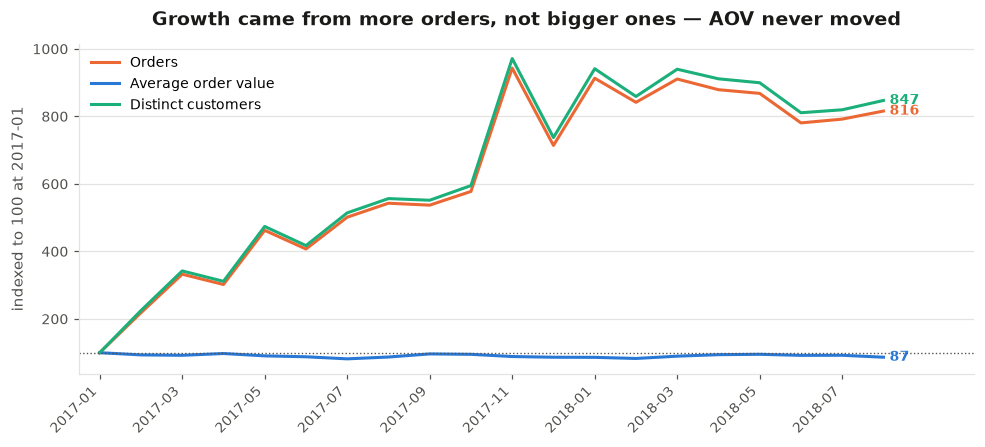

2017-01 -> 2018-08
  orders         787 ->    6,421   +715.9%
  revenue    120,098 ->  848,860   +606.8%
  AOV         152.60 ->   132.20    -13.4%


In [6]:
# Is the plateau a volume problem or a basket-size problem? Index both to 100
# at the first month so they share one scale honestly - no dual axis needed.
fig, ax = plt.subplots(figsize=(10.5, 3.9))
idx = monthly.copy()
for col, color, label in [("orders", ACCENT, "Orders"),
                          ("aov", BLUE, "Average order value"),
                          ("customers", AQUA, "Distinct customers")]:
    series = idx[col] / idx[col].iloc[0] * 100
    ax.plot(x, series, color=color, linewidth=2, label=label)
    ax.annotate(f"{series.iloc[-1]:.0f}", xy=(x[-1], series.iloc[-1]),
                xytext=(4, 0), textcoords="offset points",
                color=color, fontsize=9, fontweight="bold", va="center")

ax.axhline(100, color=INK_SOFT, linewidth=0.9, linestyle=":")
ax.set_ylabel("indexed to 100 at 2017-01")
ax.set_xticks(x[::2]); ax.set_xticklabels(monthly.order_month[::2], rotation=45, ha="right")
ax.set_title("Growth came from more orders, not bigger ones — AOV never moved")
ax.legend(loc="upper left")
ax.set_xlim(-0.5, len(monthly) + 1.2)
tidy(ax)
save(fig, "A2_growth_decomposition_indexed")
plt.show()

first, last = monthly.iloc[0], monthly.iloc[-1]
print(f"2017-01 -> 2018-08")
print(f"  orders    {first.orders:>8,.0f} -> {last.orders:>8,.0f}   {last.orders/first.orders-1:+7.1%}")
print(f"  revenue   {first.revenue:>8,.0f} -> {last.revenue:>8,.0f}   {last.revenue/first.revenue-1:+7.1%}")
print(f"  AOV       {first.aov:>8,.2f} -> {last.aov:>8,.2f}   {last.aov/first.aov-1:+7.1%}")

**Reading it.** Indexing all three to 100 at the start puts them on one honest
scale. Orders and customers rise together almost perfectly; **AOV is flat**.

Every bit of growth came from acquiring more buyers, none from persuading them
to spend more. AOV is an untouched lever — and given the ~3% repeat rate
(Section B), it may be the *only* lever left that does not depend on retention.

   saved -> reports/eda_charts/A3_revenue_by_state_pareto.png


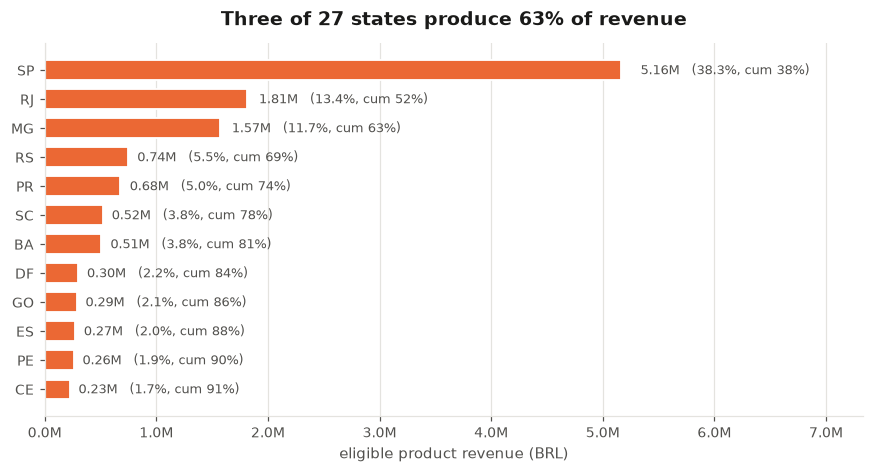

Top 3 states : 63.4% of revenue
Top 5 states : 73.9%
Bottom 14    : 7.2%

Highest AOV among the top 10 states:
                orders      revenue    aov
customer_state                            
BA                3344   507,108.83 151.65
GO                1998   287,870.46 144.08
SC                3600   518,578.28 144.05
RJ               12698 1,811,623.42 142.67


In [7]:
# Where does revenue actually come from? Pareto on states.
state_rev = (ELIG.groupby("customer_state")
             .agg(orders=("order_id", "nunique"), revenue=("order_revenue", "sum"))
             .sort_values("revenue", ascending=False))
state_rev["pct"] = state_rev.revenue / state_rev.revenue.sum() * 100
state_rev["cum_pct"] = state_rev.pct.cumsum()
state_rev["aov"] = state_rev.revenue / state_rev.orders

top = state_rev.head(12)
fig, ax = plt.subplots(figsize=(9.6, 4.4))
bars = ax.barh(top.index[::-1], top.revenue[::-1], color=ACCENT, height=0.68,
               edgecolor=SURFACE, linewidth=1.2)
for bar, (st, row) in zip(bars, list(top[::-1].iterrows())):
    ax.text(bar.get_width() * 1.02, bar.get_y() + bar.get_height()/2,
            f"  {row.revenue/1e6:,.2f}M   ({row.pct:.1f}%, cum {row.cum_pct:.0f}%)",
            va="center", fontsize=8.5, color=INK_SOFT)
ax.set_xlim(0, top.revenue.max() * 1.42)
ax.set_xlabel("eligible product revenue (BRL)")
ax.set_title("Three of 27 states produce 63% of revenue")
money(ax, axis="x", millions=True); tidy(ax, xgrid=True, ygrid=False)
save(fig, "A3_revenue_by_state_pareto")
plt.show()

print(f"Top 3 states : {state_rev.head(3).pct.sum():.1f}% of revenue")
print(f"Top 5 states : {state_rev.head(5).pct.sum():.1f}%")
print(f"Bottom 14    : {state_rev.tail(14).pct.sum():.1f}%")
print(f"\nHighest AOV among the top 10 states:")
print(state_rev.head(10).sort_values("aov", ascending=False)[["orders","revenue","aov"]].head(4).round(2).to_string())

**Reading it.** São Paulo alone is 38% of revenue; the top three states are
63%. This is the project's single largest concentration risk — larger than
seller concentration (Section D), which is the risk people usually look for.

Note too that SP has the **lowest AOV** of the major states. It wins on volume,
not basket size. Smaller, more distant states spend more per order — worth
remembering when reading the delivery analysis in Section E.

In [8]:
# Lost demand: what is cancelled/unavailable actually costing?
status = (orders.groupby("order_status")
          .agg(orders=("order_id", "nunique"), revenue=("order_revenue", "sum"))
          .sort_values("orders", ascending=False))
status["pct_orders"] = status.orders / status.orders.sum() * 100
lost = orders[~orders.revenue_eligible]
print("Order status, with the revenue attached to each:")
display(status.round(2))
print(f"Orders never fulfilled (canceled + unavailable): {len(lost):,} "
      f"({len(lost)/len(orders)*100:.2f}%)")
print(f"Product revenue attached to them: {lost.order_revenue.sum():,.2f} BRL "
      f"({lost.order_revenue.sum()/items.price.sum()*100:.2f}% of GMV)")
print("\nThese orders are excluded from revenue but NOT deleted — they are real")
print("demand that failed to convert, and Section F shows they are rated brutally.")

Order status, with the revenue attached to each:


,orders,revenue,pct_orders
order_status,,,
delivered,96478,"13,221,498.11",97.02
shipped,1107,"150,727.44",1.11
canceled,625,"95,235.27",0.63
unavailable,609,"2,007.69",0.61
invoiced,314,"61,526.37",0.32
processing,301,"60,439.22",0.30
created,5,0.00,0.01
approved,2,209.60,0.00


Orders never fulfilled (canceled + unavailable): 1,234 (1.24%)
Product revenue attached to them: 97,242.96 BRL (0.72% of GMV)

These orders are excluded from revenue but NOT deleted — they are real
demand that failed to convert, and Section F shows they are rated brutally.


---
## B · Customer Analysis

Phase 4 established the hard constraint: **only 3.12% of customers ever order
again**. This section does not try to argue around that. It asks the more
useful question — *given that, is there anything worth retaining?*

In [9]:
# Customer grain: one row per PERSON, not per order.
cust = (orders.groupby("customer_unique_id")
        .agg(orders=("order_id", "nunique"),
             revenue=("order_revenue", lambda s: s[orders.loc[s.index, "revenue_eligible"]].sum()),
             first_order=("order_date", "min"),
             last_order=("order_date", "max"),
             state=("customer_state", "first"),
             avg_review=("review_score_avg", "mean"),
             avg_delivery=("delivery_days", "mean"),
             late_rate=("is_late", "mean"))
        .reset_index())
cust["is_repeat"] = cust.orders >= 2
DATASET_END = orders.order_date.max()
cust["recency_days"] = (DATASET_END - cust.last_order).dt.days

print(f"distinct people            : {len(cust):,}")
print(f"repeat buyers (>=2 orders) : {int(cust.is_repeat.sum()):,}  ({cust.is_repeat.mean()*100:.2f}%)")
print(f"dataset end date (for recency): {DATASET_END.date()}")
print(f"total historical value     : {cust.revenue.sum():,.2f} BRL")

distinct people            : 96,096
repeat buyers (>=2 orders) : 2,997  (3.12%)
dataset end date (for recency): 2018-10-17
total historical value     : 13,494,400.74 BRL


### B1. How concentrated is customer value?

With retention near zero, the obvious fallback question is whether a small
group of high spenders carries the business. A Lorenz curve answers it
directly: plot cumulative share of customers against cumulative share of
revenue.

   saved -> reports/eda_charts/B1_customer_value_lorenz.png


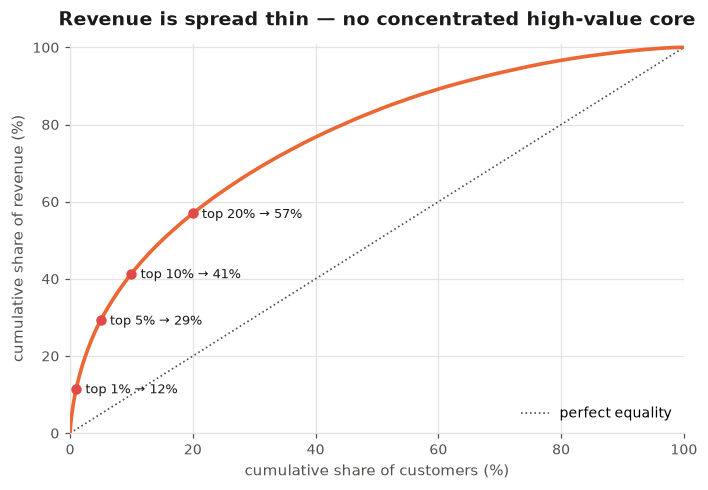

  top  1% of customers (   960 people) ->  11.5% of revenue
  top  5% of customers ( 4,804 people) ->  29.3% of revenue
  top 10% of customers ( 9,609 people) ->  41.4% of revenue
  top 20% of customers (19,219 people) ->  57.0% of revenue
  top 50% of customers (48,048 people) ->  83.7% of revenue

median customer value: 89.00 BRL
mean   customer value: 140.43 BRL

Composition of the top spenders:
  top  1% (  949 people):  92.9% placed exactly ONE order | mean orders 1.09 | mean value 1,627 BRL
  top  5% (4,749 people):  91.2% placed exactly ONE order | mean orders 1.12 | mean value 828 BRL
  top 10% (9,498 people):  91.1% placed exactly ONE order | mean orders 1.11 | mean value 584 BRL
  all customers        :  96.9% placed one order


In [10]:
cust_values = cust.revenue.sort_values(ascending=False).reset_index(drop=True)
N_CUSTOMERS = len(cust_values)
cum_rev  = cust_values.cumsum() / cust_values.sum() * 100
cum_cust = (np.arange(N_CUSTOMERS) + 1) / N_CUSTOMERS * 100

fig, ax = plt.subplots(figsize=(7.2, 4.6))
ax.plot(cum_cust, cum_rev, color=ACCENT, linewidth=2.4, zorder=3)
ax.plot([0, 100], [0, 100], color=INK_SOFT, linewidth=1.1, linestyle=":",
        zorder=2, label="perfect equality")

for pct in (1, 5, 10, 20):
    i = int(N_CUSTOMERS * pct / 100) - 1
    y = cum_rev.iloc[i]
    ax.scatter([pct], [y], color=CRITICAL, s=34, zorder=5)
    ax.annotate(f"top {pct}% → {y:.0f}%", xy=(pct, y), xytext=(6, -3),
                textcoords="offset points", fontsize=8.5, color=INK)

ax.set_xlabel("cumulative share of customers (%)")
ax.set_ylabel("cumulative share of revenue (%)")
ax.set_title("Revenue is spread thin — no concentrated high-value core")
ax.set_xlim(0, 100); ax.set_ylim(0, 101)
ax.legend(loc="lower right")
tidy(ax, xgrid=True)
save(fig, "B1_customer_value_lorenz")
plt.show()

for pct in (1, 5, 10, 20, 50):
    i = int(N_CUSTOMERS * pct / 100) - 1
    print(f"  top {pct:>2}% of customers ({int(N_CUSTOMERS*pct/100):>6,} people) -> {cum_rev.iloc[i]:>5.1f}% of revenue")
print(f"\nmedian customer value: {cust.revenue.median():,.2f} BRL")
print(f"mean   customer value: {cust.revenue.mean():,.2f} BRL")

# The concentration figure alone is misleading. The decisive question is
# WHO the top spenders are: loyal repeat buyers, or one-off big purchases?
print("\nComposition of the top spenders:")
ranked = cust[cust.revenue > 0].sort_values("revenue", ascending=False)
for pct in (1, 5, 10):
    top = ranked.head(int(len(ranked) * pct / 100))
    print(f"  top {pct:>2}% ({len(top):>5,} people): "
          f"{top.orders.eq(1).mean()*100:5.1f}% placed exactly ONE order | "
          f"mean orders {top.orders.mean():.2f} | mean value {top.revenue.mean():,.0f} BRL")
print(f"  all customers        : {ranked.orders.eq(1).mean()*100:5.1f}% placed one order")

**Reading it.** Value *is* concentrated, though less sharply than the classic
Pareto rule: the top 10% of customers hold **41%** of revenue and the top 20%
hold **57%** — not the 80% a textbook 80/20 would predict.

**But the concentration figure alone is misleading, and the composition check
below is the real finding: 93% of the top 1% of spenders placed exactly one
order.** Their mean is 1.09 orders at 1,627 BRL. These are not loyal
customers; they are strangers who made a single expensive purchase and never
came back.

That changes the strategic conclusion entirely. A VIP or loyalty programme
aimed at "best customers" would be targeting people who have already left,
and who showed no loyalty behaviour to reward in the first place. The
opportunity is not **depth** (extract more from loyal spenders — there are
almost none) but **breadth**: converting any first purchase into a second one.

This is the same conclusion the RFM segmentation reaches independently in B2,
by a different route.

### B2. RFM segmentation

**Method, including one deliberate departure from the textbook.**

- **R (Recency)** — days since the person's last order, measured against the
  dataset's end date (2018-10-17), not today. Scored 1–5 by quintile; more
  recent is better.
- **M (Monetary)** — total historical revenue, scored 1–5 by quintile.
- **F (Frequency)** — order count. **Not quintiles.**

Why F is different: 96.88% of people have exactly one order. Running
`qcut` on a near-constant column would split it into five arbitrary buckets
and invent distinctions that do not exist. F is therefore a small honest
ordinal: **1 order → 1, 2 orders → 3, 3+ orders → 5**.

This limitation is stated wherever RFM appears in this project. Pretending the
F dimension is informative here would be fabrication.

In [11]:
rfm = cust[["customer_unique_id", "recency_days", "orders", "revenue", "state"]].copy()
rfm = rfm[rfm.revenue > 0]      # RFM needs a monetary value to score

# R: fewer days = better. rank(method='first') breaks ties deterministically so
# qcut cannot fail on duplicate bin edges.
rfm["r_score"] = pd.qcut(rfm.recency_days.rank(method="first", ascending=False),
                         5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["m_score"] = pd.qcut(rfm.revenue.rank(method="first"),
                         5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["f_score"] = np.select([rfm.orders >= 3, rfm.orders == 2], [5, 3], default=1)

def segment(r):
    if r.r_score >= 4 and r.f_score >= 3 and r.m_score >= 4: return "Champions"
    if r.r_score >= 3 and r.f_score >= 3:                    return "Loyal Customers"
    if r.r_score >= 4 and r.f_score == 1 and r.m_score >= 3: return "Potential Loyalists"
    if r.r_score <= 2 and r.m_score >= 4:                    return "At Risk"
    if r.r_score <= 2:                                       return "Lost"
    return "Needs Attention"

rfm["segment"] = rfm.apply(segment, axis=1)

seg = (rfm.groupby("segment")
       .agg(customers=("customer_unique_id", "count"),
            avg_recency=("recency_days", "mean"),
            avg_orders=("orders", "mean"),
            avg_value=("revenue", "mean"),
            revenue=("revenue", "sum"))
       .sort_values("revenue", ascending=False))
seg["pct_customers"] = seg.customers / seg.customers.sum() * 100
seg["pct_revenue"]   = seg.revenue / seg.revenue.sum() * 100
display(seg.round(2))
print(f"\nF-score distribution (showing why quintiles were impossible):")
print(rfm.f_score.value_counts().sort_index().to_string())

,customers,avg_recency,avg_orders,avg_value,revenue,pct_customers,pct_revenue
segment,,,,,,,
Potential Loyalists,21989,140.30,1.00,208.21,"4,578,252.38",23.15,33.93
At Risk,14760,443.68,1.06,279.89,"4,131,120.14",15.54,30.61
Needs Attention,33069,210.96,1.00,89.90,"2,972,977.17",34.82,22.03
Lost,23233,444.70,1.01,56.03,"1,301,688.68",24.46,9.65
Champions,979,136.16,2.20,329.29,"322,372.08",1.03,2.39
Loyal Customers,953,223.29,2.07,197.26,"187,990.29",1.00,1.39



F-score distribution (showing why quintiles were impossible):
f_score
1    91994
3     2738
5      251


   saved -> reports/eda_charts/B2_rfm_segments_customers_vs_revenue.png


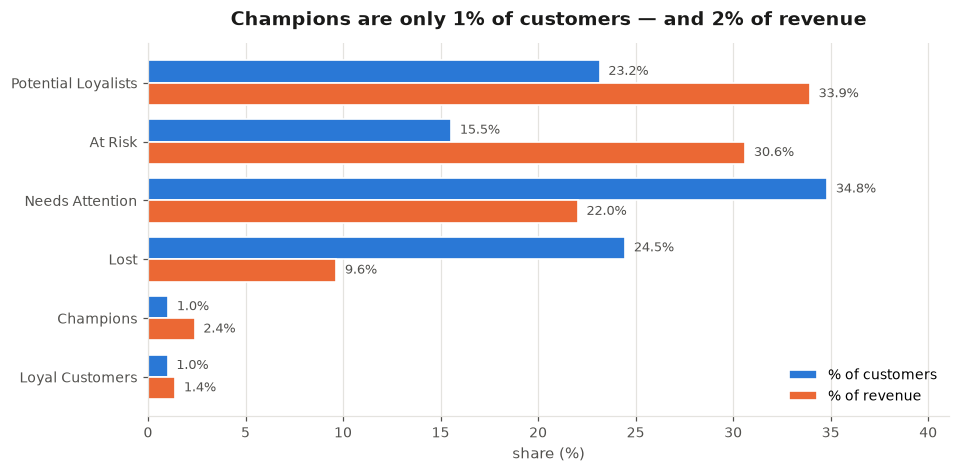

Potential Loyalists: 21,989 people (23.2%) holding 33.9% of revenue
Champions          :    979 people (1.0%) holding 2.4% of revenue


In [12]:
# Two bars per segment: share of customers vs share of revenue. The gap between
# them is the insight - a segment worth more than its size, or less.
s = seg.sort_values("pct_revenue", ascending=True)
y = np.arange(len(s)); h = 0.38

fig, ax = plt.subplots(figsize=(9.4, 4.4))
b1 = ax.barh(y + h/2, s.pct_customers, height=h, color=BLUE,
             edgecolor=SURFACE, linewidth=1.1, label="% of customers")
b2 = ax.barh(y - h/2, s.pct_revenue, height=h, color=ACCENT,
             edgecolor=SURFACE, linewidth=1.1, label="% of revenue")
for bars in (b1, b2):
    for bar in bars:
        ax.text(bar.get_width() + 0.45, bar.get_y() + bar.get_height()/2,
                f"{bar.get_width():.1f}%", va="center", fontsize=8.3, color=INK_SOFT)

ax.set_yticks(y); ax.set_yticklabels(s.index)
ax.set_xlabel("share (%)")
ax.set_xlim(0, max(s.pct_customers.max(), s.pct_revenue.max()) * 1.18)
ax.set_title("Champions are only 1% of customers — and 2% of revenue")
ax.legend(loc="lower right")
tidy(ax, xgrid=True, ygrid=False)
save(fig, "B2_rfm_segments_customers_vs_revenue")
plt.show()

pl = seg.loc["Potential Loyalists"]
ch = seg.loc["Champions"]
print(f"Potential Loyalists: {pl.customers:>6,.0f} people ({pl.pct_customers:.1f}%) "
      f"holding {pl.pct_revenue:.1f}% of revenue")
print(f"Champions          : {ch.customers:>6,.0f} people ({ch.pct_customers:.1f}%) "
      f"holding {ch.pct_revenue:.1f}% of revenue")

**Reading it.** The usual RFM playbook says *protect your Champions*. Here
that advice would be close to worthless: Champions are 957 people holding
**2.3%** of revenue.

The segment that matters is **Potential Loyalists** — recent, decent spend,
exactly one order. They are 23% of customers and **34% of revenue**, the
largest revenue block in the business. Every one of them is a first-purchase
customer who has not yet been lost.

**So the retention question is not "how do we keep our best customers?" but
"how do we get a second order out of a recent first-time buyer?"** That is a
different programme entirely — onboarding and follow-up, not VIP perks.

### B3. Cohort retention

Group people by the month of their first purchase, then track how many return
in later months. **Expect very low numbers** — that is the honest result, not
a broken calculation.

One caveat that must be read with the chart: **right-censoring**. Someone
acquired in August 2018 had almost no time to return before the data ends, so
later cohorts look worse than they are. Compare *within* a column, not across.

   saved -> reports/eda_charts/B3_cohort_retention_heatmap.png


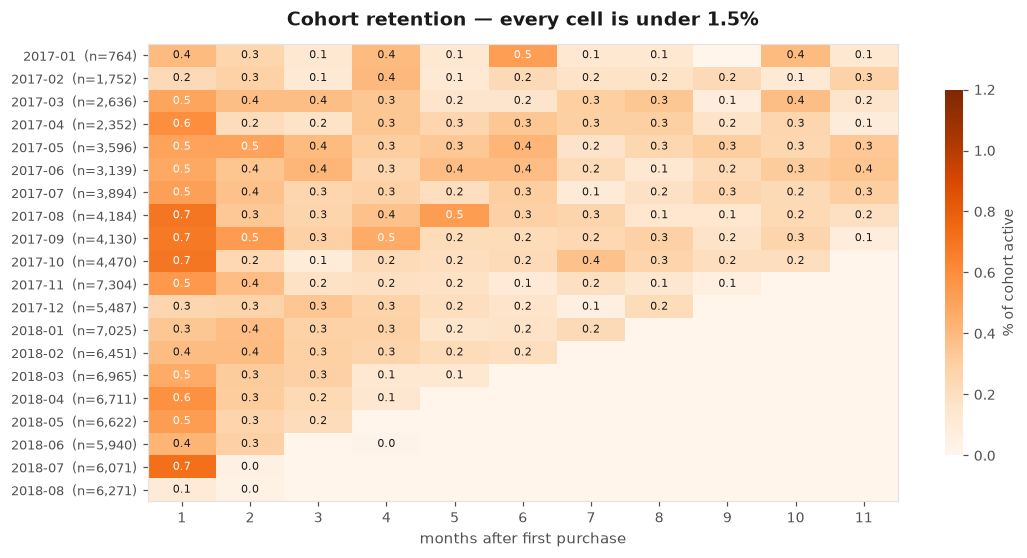

Share of each cohort that EVER returned:
  best  : 2017-01  4.32%
  worst : 2018-08  0.13%   (later cohorts are right-censored)
  mean across 2017 cohorts: 3.07%


In [13]:
first_order = orders.groupby("customer_unique_id").order_date.min().rename("first_date")
act = orders[["customer_unique_id", "order_date"]].merge(first_order, on="customer_unique_id")
act["cohort"] = act.first_date.dt.to_period("M").astype(str)
act["period"] = ((act.order_date.dt.year - act.first_date.dt.year) * 12
                 + (act.order_date.dt.month - act.first_date.dt.month))

cohort_counts = (act[act.cohort.between("2017-01", "2018-08")]
                 .groupby(["cohort", "period"]).customer_unique_id.nunique().unstack(fill_value=0))
sizes = cohort_counts[0]
retention = cohort_counts.div(sizes, axis=0) * 100
ret = retention.loc[:, 0:11]

fig, ax = plt.subplots(figsize=(11, 5.4))
data = ret.values[:, 1:]          # drop month 0 (always 100%) so the scale is usable
im = ax.imshow(data, aspect="auto", cmap="Oranges", vmin=0, vmax=max(1.2, np.nanmax(data)))
ax.set_xticks(range(data.shape[1])); ax.set_xticklabels(range(1, data.shape[1] + 1))
ax.set_yticks(range(len(ret))); ax.set_yticklabels(
    [f"{c}  (n={int(sizes.loc[c]):,})" for c in ret.index], fontsize=8.5)
for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        val = data[i, j]
        if val > 0:
            ax.text(j, i, f"{val:.1f}", ha="center", va="center", fontsize=7.4,
                    color=INK if val < np.nanmax(data) * 0.6 else SURFACE)
ax.set_xlabel("months after first purchase")
ax.set_title("Cohort retention — every cell is under 1.5%")
ax.grid(False)
cb = fig.colorbar(im, ax=ax, shrink=0.8); cb.set_label("% of cohort active", fontsize=9)
cb.outline.set_visible(False)
save(fig, "B3_cohort_retention_heatmap")
plt.show()

ever = act[act.period > 0].groupby("cohort").customer_unique_id.nunique() / sizes * 100
ever = ever.dropna()
print("Share of each cohort that EVER returned:")
print(f"  best  : {ever.idxmax()}  {ever.max():.2f}%")
print(f"  worst : {ever.idxmin()}  {ever.min():.2f}%   (later cohorts are right-censored)")
print(f"  mean across 2017 cohorts: {ever[ever.index < '2018-01'].mean():.2f}%")

**Reading it.** Every single cell is below 1.5%. There is no month, no cohort
and no point in the customer lifecycle where meaningful return behaviour
appears.

This is a genuine finding about the business, not a data problem: **Olist in
this period operated as a pure acquisition marketplace.** Customers arrive via
search for a specific product, buy once, and do not form a relationship with
the platform.

The honest strategic read: retention programmes would be building on sand.
The achievable levers are AOV (Section A2, flat) and the delivery experience
(Sections E and F), which at least correlates with whether people come back at
all.

In [14]:
# Do repeat buyers differ from one-time buyers? If so, that difference is a lever.
cmp_ = (cust.assign(group=np.where(cust.is_repeat, "Repeat buyer", "One-time buyer"))
        .groupby("group")
        .agg(people=("customer_unique_id", "count"),
             avg_value=("revenue", "mean"),
             avg_review=("avg_review", "mean"),
             avg_delivery=("avg_delivery", "mean"),
             late_rate=("late_rate", "mean")))
cmp_["late_pct"] = cmp_.late_rate * 100
display(cmp_.drop(columns="late_rate").round(3))

one, rep = cmp_.loc["One-time buyer"], cmp_.loc["Repeat buyer"]
print(f"Repeat buyers experienced {(1 - rep.late_rate/one.late_rate)*100:.1f}% fewer late deliveries")
print(f"and rated their orders {rep.avg_review - one.avg_review:+.3f} stars higher.")
print("\nCORRELATION, NOT CAUSATION. A good delivery may encourage a second order,")
print("or frequent buyers may simply cluster in well-served cities. This data")
print("cannot separate the two, and Section E shows geography matters a great deal.")

,people,avg_value,avg_review,avg_delivery,late_pct
group,,,,,
One-time buyer,93099,136.65,4.08,12.57,8.19
Repeat buyer,2997,257.71,4.12,12.34,7.13


Repeat buyers experienced 12.9% fewer late deliveries
and rated their orders +0.031 stars higher.

CORRELATION, NOT CAUSATION. A good delivery may encourage a second order,
or frequent buyers may simply cluster in well-served cities. This data
cannot separate the two, and Section E shows geography matters a great deal.


---
## C · Product & Category Analysis

### C1. Which categories carry the business?

In [15]:
cat = (ELIG_ITEMS.groupby("product_category_name_english")
       .agg(items=("price", "size"),
            orders=("order_id", "nunique"),
            revenue=("price", "sum"),
            avg_price=("price", "mean"))
       .sort_values("revenue", ascending=False))
cat["pct"] = cat.revenue / cat.revenue.sum() * 100
cat["cum_pct"] = cat.pct.cumsum()

print(f"categories with eligible revenue: {len(cat)}")
print(f"top 10 share : {cat.head(10).pct.sum():.1f}%")
print(f"top 20 share : {cat.head(20).pct.sum():.1f}%")
print(f"categories needed to reach 80% of revenue: {int((cat.cum_pct < 80).sum()) + 1}")
display(cat.head(10).round(2))

categories with eligible revenue: 74
top 10 share : 62.4%
top 20 share : 84.0%
categories needed to reach 80% of revenue: 18


,items,orders,revenue,avg_price,pct,cum_pct
product_category_name_english,,,,,,
health_beauty,9634,8800,"1,255,695.13",130.34,9.31,9.31
watches_gifts,5970,5604,"1,198,185.21",200.70,8.88,18.18
bed_bath_table,11097,9399,"1,035,964.06",93.36,7.68,25.86
sports_leisure,8590,7673,"979,740.92",114.06,7.26,33.12
computers_accessories,7781,6654,"904,322.02",116.22,6.70,39.82
furniture_decor,8298,6425,"727,465.05",87.67,5.39,45.21
housewares,6915,5847,"626,825.80",90.65,4.65,49.86
cool_stuff,3779,3616,"620,770.49",164.27,4.60,54.46
auto,4204,3872,"586,585.73",139.53,4.35,58.81


   saved -> reports/eda_charts/C1_category_revenue_and_concentration.png


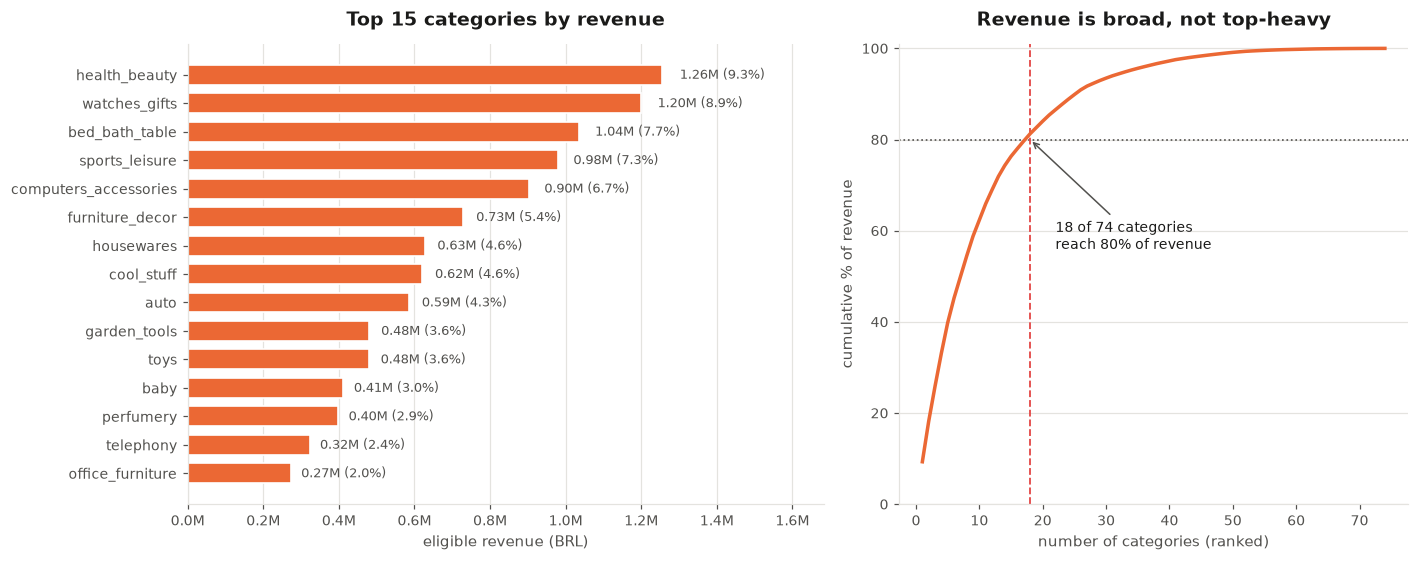

In [16]:
fig, (axL, axR) = plt.subplots(1, 2, figsize=(13, 5.2),
                               gridspec_kw={"width_ratios": [1.25, 1]})

t = cat.head(15)
bars = axL.barh(t.index[::-1], t.revenue[::-1], color=ACCENT, height=0.70,
                edgecolor=SURFACE, linewidth=1.1)
for bar, val, pct in zip(bars, t.revenue[::-1], t.pct[::-1]):
    axL.text(bar.get_width() * 1.02, bar.get_y() + bar.get_height()/2,
             f"  {val/1e6:.2f}M ({pct:.1f}%)", va="center", fontsize=8.2, color=INK_SOFT)
axL.set_xlim(0, t.revenue.max() * 1.34)
axL.set_xlabel("eligible revenue (BRL)")
axL.set_title("Top 15 categories by revenue")
money(axL, axis="x", millions=True); tidy(axL, xgrid=True, ygrid=False)

n = np.arange(1, len(cat) + 1)
axR.plot(n, cat.cum_pct.values, color=ACCENT, linewidth=2.3, zorder=3)
axR.axhline(80, color=INK_SOFT, linestyle=":", linewidth=1.1)
k = int((cat.cum_pct < 80).sum()) + 1
axR.axvline(k, color=CRITICAL, linestyle="--", linewidth=1.2)
axR.annotate(f"{k} of {len(cat)} categories\nreach 80% of revenue",
             xy=(k, 80), xytext=(k + 4, 56), fontsize=9, color=INK,
             arrowprops=dict(arrowstyle="->", color=INK_SOFT, lw=1))
axR.set_xlabel("number of categories (ranked)")
axR.set_ylabel("cumulative % of revenue")
axR.set_title("Revenue is broad, not top-heavy")
axR.set_ylim(0, 101)
tidy(axR)

plt.tight_layout()
save(fig, "C1_category_revenue_and_concentration")
plt.show()

**Reading it.** No category dominates — the largest, `health_beauty`, is only
9.3% of revenue, and it takes **26 of 74 categories** to reach 80%.

Compare that with geography (Section A3), where 3 of 27 states reach 63%.
**Category risk is genuinely low; geographic risk is high.** That is the
opposite of what most retail intuition expects, and it means diversification
effort belongs in logistics and regional reach, not in the catalogue.

   saved -> reports/eda_charts/C2_category_growth_vs_decline.png


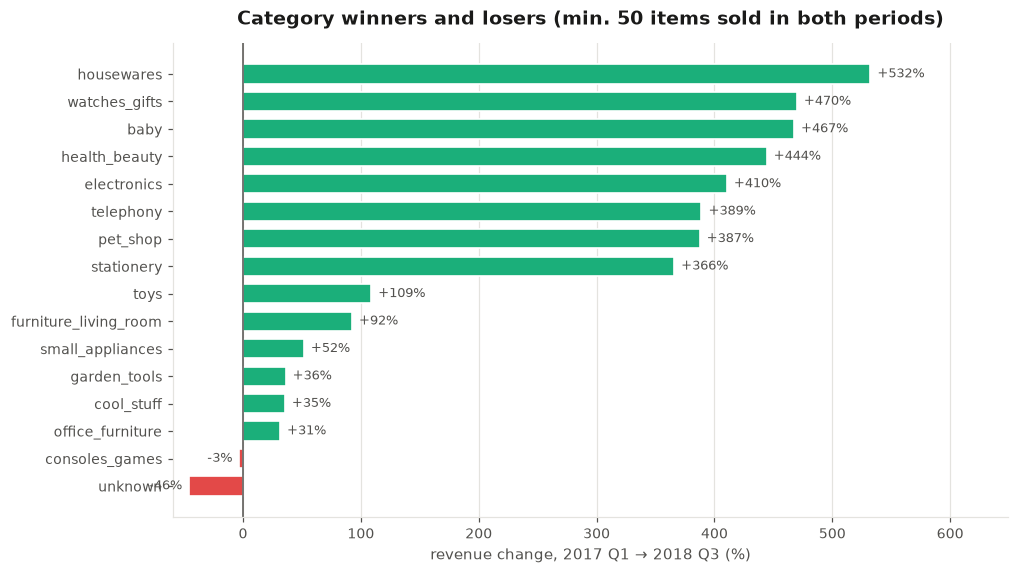

categories meeting the volume floor: 24
  growing : 22
  shrinking: 2

Fastest growth: housewares  +532%
Sharpest decline: unknown  -46%


In [17]:
# Which categories are growing, and which are dying? Compare the first and last
# quarter of the stable window. A minimum volume floor in BOTH periods keeps
# tiny categories from producing meaningless percentage swings.
q1 = ELIG_ITEMS[ELIG_ITEMS.order_month.between("2017-01", "2017-03")]
q2 = ELIG_ITEMS[ELIG_ITEMS.order_month.between("2018-06", "2018-08")]
g = pd.DataFrame({
    "rev_2017q1": q1.groupby("product_category_name_english").price.sum(),
    "rev_2018q3": q2.groupby("product_category_name_english").price.sum(),
    "n_2017q1":   q1.groupby("product_category_name_english").price.size(),
    "n_2018q3":   q2.groupby("product_category_name_english").price.size(),
}).fillna(0)
g = g[(g.n_2017q1 >= 50) & (g.n_2018q3 >= 50)].copy()
g["change_pct"] = (g.rev_2018q3 / g.rev_2017q1 - 1) * 100
g = g.sort_values("change_pct")

show = pd.concat([g.head(8), g.tail(8)])
colors = [CRITICAL if v < 0 else GOOD for v in show.change_pct]
fig, ax = plt.subplots(figsize=(9.8, 5.6))
bars = ax.barh(show.index, show.change_pct, color=colors, height=0.70,
               edgecolor=SURFACE, linewidth=1.1)
for bar, v in zip(bars, show.change_pct):
    off = 6 if v >= 0 else -6
    ax.text(v + off, bar.get_y() + bar.get_height()/2, f"{v:+.0f}%",
            va="center", ha="left" if v >= 0 else "right", fontsize=8.4, color=INK_SOFT)
ax.axvline(0, color=INK_SOFT, linewidth=1)
ax.set_xlabel("revenue change, 2017 Q1 → 2018 Q3 (%)")
ax.set_title("Category winners and losers (min. 50 items sold in both periods)")
ax.set_xlim(show.change_pct.min() * 1.3, show.change_pct.max() * 1.22)
tidy(ax, xgrid=True, ygrid=False)
save(fig, "C2_category_growth_vs_decline")
plt.show()

print(f"categories meeting the volume floor: {len(g)}")
print(f"  growing : {int((g.change_pct > 0).sum())}")
print(f"  shrinking: {int((g.change_pct < 0).sum())}")
print(f"\nFastest growth: {g.index[-1]}  {g.change_pct.iloc[-1]:+.0f}%")
print(f"Sharpest decline: {g.index[0]}  {g.change_pct.iloc[0]:+.0f}%")

---
## D · Seller Analysis

Two questions: how dependent is the platform on any one seller, and which
sellers should management actually call?

In [18]:
# Revenue per (seller, order) first, so an order spanning several sellers is
# never counted twice.
so = (ELIG_ITEMS.groupby(["seller_id", "order_id"])
      .agg(seller_revenue=("price", "sum"), items=("price", "size"))
      .reset_index())
so = so.merge(orders[["order_id", "delivery_days", "is_late", "review_score_avg",
                      "delivery_measurable"]], on="order_id", how="left")

sell = (so.groupby("seller_id")
        .agg(orders=("order_id", "nunique"),
             items=("items", "sum"),
             revenue=("seller_revenue", "sum"),
             avg_delivery=("delivery_days", "mean"),
             late_rate=("is_late", "mean"),
             avg_review=("review_score_avg", "mean"))
        .reset_index()
        .merge(sellers[["seller_id", "seller_state"]], on="seller_id", how="left"))
sell["late_pct"] = sell.late_rate * 100
sell["pct_revenue"] = sell.revenue / sell.revenue.sum() * 100
sell = sell.sort_values("revenue", ascending=False)

print(f"sellers with eligible revenue: {len(sell):,} of {len(sellers):,}")
print(f"  (the rest had only canceled/unavailable orders)")
print(f"largest single seller: {sell.pct_revenue.iloc[0]:.2f}% of revenue")
print(f"top 10 sellers       : {sell.head(10).pct_revenue.sum():.1f}%")
print(f"top 100 sellers      : {sell.head(100).pct_revenue.sum():.1f}%")

sellers with eligible revenue: 3,053 of 3,095
  (the rest had only canceled/unavailable orders)
largest single seller: 1.70% of revenue
top 10 sellers       : 13.2%
top 100 sellers      : 45.3%


   saved -> reports/eda_charts/D1_seller_revenue_concentration.png


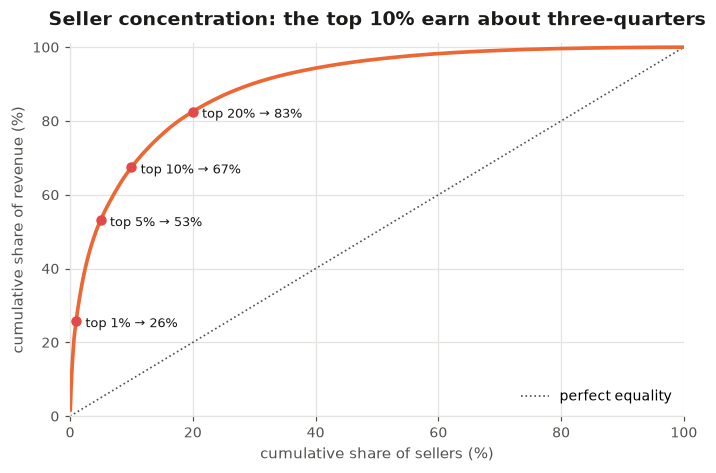

  top  1% (  30 sellers) ->  25.8% of revenue
  top  5% ( 152 sellers) ->  53.1% of revenue
  top 10% ( 305 sellers) ->  67.4% of revenue
  top 25% ( 763 sellers) ->  87.0% of revenue
  top 50% (1,526 sellers) ->  96.8% of revenue


In [19]:
cum = sell.revenue.cumsum() / sell.revenue.sum() * 100
xs  = (np.arange(len(sell)) + 1) / len(sell) * 100

fig, ax = plt.subplots(figsize=(7.2, 4.4))
ax.plot(xs, cum.values, color=ACCENT, linewidth=2.4, zorder=3)
ax.plot([0, 100], [0, 100], color=INK_SOFT, linestyle=":", linewidth=1.1,
        label="perfect equality")
for pct in (1, 5, 10, 20):
    i = max(int(len(sell) * pct / 100) - 1, 0)
    ax.scatter([pct], [cum.iloc[i]], color=CRITICAL, s=34, zorder=5)
    ax.annotate(f"top {pct}% → {cum.iloc[i]:.0f}%", xy=(pct, cum.iloc[i]),
                xytext=(6, -4), textcoords="offset points", fontsize=8.5, color=INK)
ax.set_xlabel("cumulative share of sellers (%)")
ax.set_ylabel("cumulative share of revenue (%)")
ax.set_title("Seller concentration: the top 10% earn about three-quarters")
ax.set_xlim(0, 100); ax.set_ylim(0, 101)
ax.legend(loc="lower right")
tidy(ax, xgrid=True)
save(fig, "D1_seller_revenue_concentration")
plt.show()

for pct in (1, 5, 10, 25, 50):
    i = max(int(len(sell) * pct / 100) - 1, 0)
    print(f"  top {pct:>2}% ({int(len(sell)*pct/100):>4,} sellers) -> {cum.iloc[i]:>5.1f}% of revenue")

**Reading it.** No single seller is critical — the largest holds under 2% of
revenue, so losing any one of them is survivable. But the *tier* is
concentrated: the top 10% of sellers earn roughly three-quarters of revenue.

So the risk is not "one seller leaves" but "the quality of a few hundred
sellers determines the platform's reputation". That makes the next chart the
operational one.

   saved -> reports/eda_charts/D2_seller_scorecard_late_vs_review.png


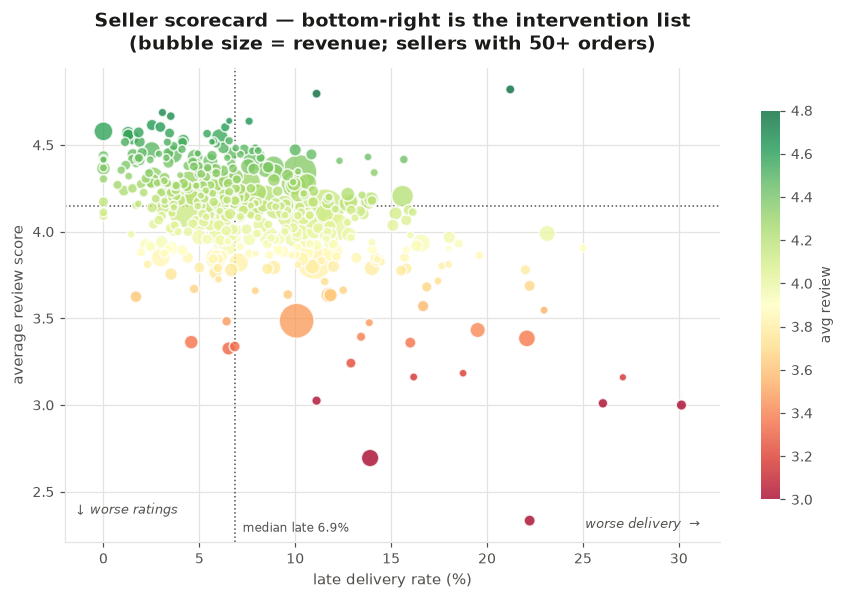

sellers with 50+ orders: 428
correlation between late rate and review score: -0.522

Intervention list — high volume, poor rating:
                       seller_id seller_state  orders    revenue  late_pct  avg_review
7c67e1448b00f6e969d365cea6b010ab           SP     982 187,923.89     10.07        3.49
2eb70248d66e0e3ef83659f71b244378           SP     202  42,628.61     13.90        2.69
1835b56ce799e6a4dc4eddc053f04066           SP     423  33,344.21     11.75        3.63
855668e0971d4dfd7bef1b6a4133b41b           SP     310  31,918.21     14.00        3.79
88460e8ebdecbfecb5f9601833981930           PR     247  31,396.65     19.51        3.43
70a12e78e608ac31179aea7f8422044b           SP     315  30,858.53     10.90        3.80


In [20]:
# The intervention chart: late rate against review score, for sellers big
# enough for the numbers to be stable. Bubble size = revenue.
big = sell[(sell.orders >= 50) & sell.avg_review.notna() & sell.late_pct.notna()].copy()

fig, ax = plt.subplots(figsize=(9.6, 5.6))
sizes = (big.revenue / big.revenue.max() * 620) + 18
sc = ax.scatter(big.late_pct, big.avg_review, s=sizes, c=big.avg_review,
                cmap="RdYlGn", vmin=3.0, vmax=4.8, alpha=0.78,
                edgecolors=SURFACE, linewidths=1.1, zorder=3)

med_late = big.late_pct.median(); med_rev = big.avg_review.median()
ax.axvline(med_late, color=INK_SOFT, linestyle=":", linewidth=1)
ax.axhline(med_rev,  color=INK_SOFT, linestyle=":", linewidth=1)
ax.text(med_late + 0.4, ax.get_ylim()[0] + 0.06, f"median late {med_late:.1f}%",
        fontsize=8, color=INK_SOFT)

# Per-point labels were tried and removed: at this density they collided with
# each other and with the axis. The chart's job is to show the PATTERN; the
# printed table below names the specific sellers, which is easier to read and
# easier to act on than text crammed into a scatter.
ax.annotate("worse delivery  →", xy=(0.97, 0.03), xycoords="axes fraction",
            ha="right", fontsize=8.5, color=INK_SOFT, style="italic")
ax.annotate("↓ worse ratings", xy=(0.015, 0.06), xycoords="axes fraction",
            ha="left", fontsize=8.5, color=INK_SOFT, style="italic")
ax.set_xlim(big.late_pct.min() - 2, big.late_pct.max() + 2)

ax.set_xlabel("late delivery rate (%)")
ax.set_ylabel("average review score")
ax.set_title("Seller scorecard — bottom-right is the intervention list\n(bubble size = revenue; sellers with 50+ orders)")
cb = fig.colorbar(sc, ax=ax, shrink=0.82); cb.set_label("avg review", fontsize=9)
cb.outline.set_visible(False)
tidy(ax, xgrid=True)
save(fig, "D2_seller_scorecard_late_vs_review")
plt.show()

print(f"sellers with 50+ orders: {len(big):,}")
corr = big[["late_pct", "avg_review"]].corr().iloc[0, 1]
print(f"correlation between late rate and review score: {corr:.3f}")
print("\nIntervention list — high volume, poor rating:")
print(big[(big.avg_review < 3.8) & (big.orders >= 100)]
      .nlargest(6, "revenue")[["seller_id","seller_state","orders","revenue","late_pct","avg_review"]]
      .round(2).to_string(index=False))

**Reading it.** The correlation between a seller's late rate and their review
score is real but **moderate** — late delivery explains part of a bad rating,
not all of it. Several sellers sit bottom-left: low late rate, poor reviews.
Something other than logistics is wrong there (product quality, listing
accuracy), and that is a different intervention.

The bottom-right quadrant is the actionable list: high volume, high late rate,
low scores. It is short enough for a person to work through.

**Caveat carried from Phase 4:** a review attaches to the *order*, not the
seller. In a multi-seller order every seller inherits the same score, so these
figures are indicative rather than a clean per-seller measurement.

---
## E · Delivery & Operations

Phase 4 found that orders arrive **11.18 days early on average** while
on-time performance reads 91.89%. That combination is suspicious — it suggests
the promise is padded rather than the logistics being fast. This section tests
that.

   saved -> reports/eda_charts/E1_promised_vs_actual_delivery.png

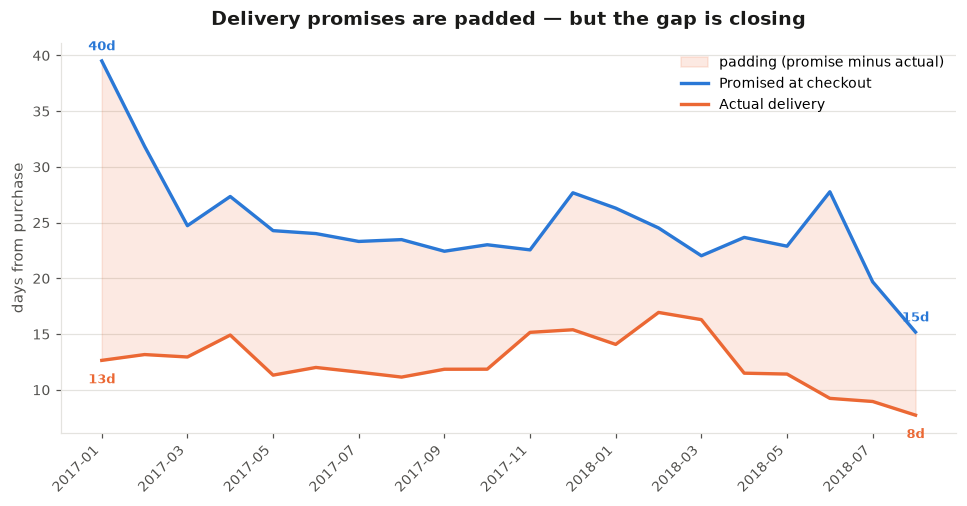

2017-01: promised  39.5d, actual  12.6d  -> padding  26.9d
2018-08: promised  15.2d, actual   7.7d  -> padding   7.5d

actual delivery improved 39%
promise tightened        62%
mean padding across window: 12.3 days


In [21]:
d = DELIVERED.copy()
d["promised_days"] = (pd.to_datetime(d.order_estimated_delivery_date)
                      - d.order_purchase_timestamp).dt.total_seconds() / 86400

by_month = (d[d.in_stable_window].groupby("order_month")
            .agg(orders=("order_id", "size"),
                 actual=("delivery_days", "mean"),
                 promised=("promised_days", "mean"),
                 late_pct=("is_late", "mean"))
            .reset_index())
by_month["late_pct"] *= 100
by_month["gap"] = by_month.promised - by_month.actual

fig, ax = plt.subplots(figsize=(10.5, 4.6))
x = np.arange(len(by_month))
ax.fill_between(x, by_month.actual, by_month.promised, color=ACCENT, alpha=0.14,
                zorder=1, label="padding (promise minus actual)")
ax.plot(x, by_month.promised, color=BLUE, linewidth=2.2, zorder=3, label="Promised at checkout")
ax.plot(x, by_month.actual,   color=ACCENT, linewidth=2.2, zorder=3, label="Actual delivery")
for i in (0, len(by_month) - 1):
    ax.annotate(f"{by_month.promised.iloc[i]:.0f}d", xy=(i, by_month.promised.iloc[i]),
                xytext=(0, 7), textcoords="offset points", ha="center",
                fontsize=8.6, color=BLUE, fontweight="bold")
    ax.annotate(f"{by_month.actual.iloc[i]:.0f}d", xy=(i, by_month.actual.iloc[i]),
                xytext=(0, -15), textcoords="offset points", ha="center",
                fontsize=8.6, color=ACCENT, fontweight="bold")
ax.set_xticks(x[::2]); ax.set_xticklabels(by_month.order_month[::2], rotation=45, ha="right")
ax.set_ylabel("days from purchase")
ax.set_title("Delivery promises are padded — but the gap is closing")
ax.legend(loc="upper right")
tidy(ax)
save(fig, "E1_promised_vs_actual_delivery")
plt.show()

f_, l_ = by_month.iloc[0], by_month.iloc[-1]
print(f"{f_.order_month}: promised {f_.promised:5.1f}d, actual {f_.actual:5.1f}d  -> padding {f_.gap:5.1f}d")
print(f"{l_.order_month}: promised {l_.promised:5.1f}d, actual {l_.actual:5.1f}d  -> padding {l_.gap:5.1f}d")
print(f"\nactual delivery improved {1 - l_.actual/f_.actual:.0%}")
print(f"promise tightened        {1 - l_.promised/f_.promised:.0%}")
print(f"mean padding across window: {by_month.gap.mean():.1f} days")

**Reading it.** Confirmed. In January 2017 Olist quoted **39.5 days** and
delivered in 12.6. By August 2018 it quoted 15.2 and delivered in **7.7**.

Both numbers improved, but note *which improved faster*: actual delivery got
39% quicker while the quoted promise tightened 62%. The padding is being
deliberately squeezed out, and the company is converging on honest estimates.

Whether the remaining ~7 days of padding costs conversions at checkout is not
answerable from this dataset — there is no browsing or cart data. It is a
testable hypothesis, not a finding.

   saved -> reports/eda_charts/E2_delivery_by_state.png


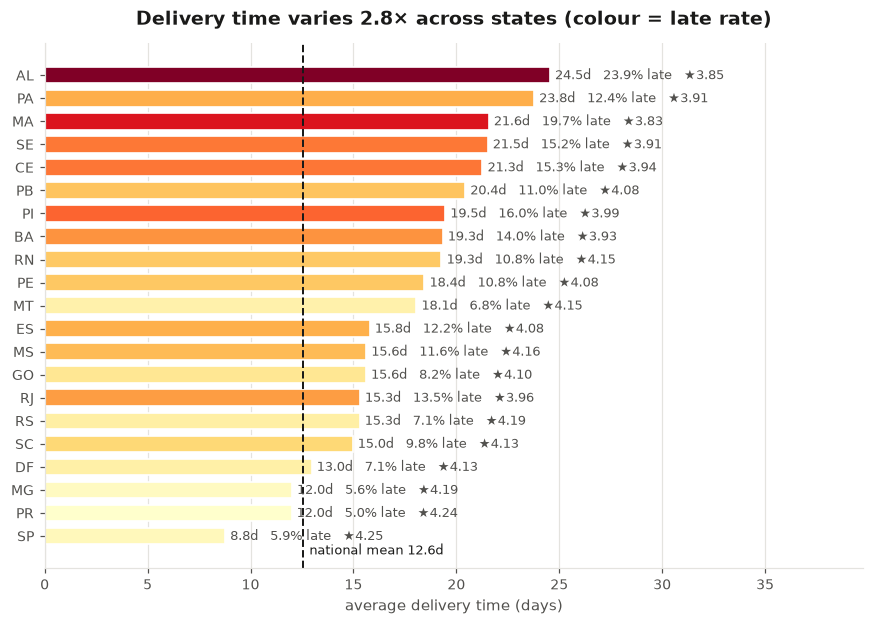

fastest: SP  8.8 days, 5.9% late
slowest: AL 24.5 days, 23.9% late
spread : 2.8x

correlation, delivery days vs review score across states: -0.830


In [22]:
state = (d.groupby("customer_state")
         .agg(orders=("order_id", "size"),
              avg_days=("delivery_days", "mean"),
              late_pct=("is_late", "mean"),
              avg_review=("review_score_avg", "mean"))
         .query("orders >= 300"))
state["late_pct"] *= 100
state = state.sort_values("avg_days")

fig, ax = plt.subplots(figsize=(9.6, 6.2))
norm = plt.Normalize(state.late_pct.min(), state.late_pct.max())
cols = plt.cm.YlOrRd(norm(state.late_pct.values))
bars = ax.barh(state.index, state.avg_days, color=cols, height=0.72,
               edgecolor=SURFACE, linewidth=1.1)
for bar, (st, r) in zip(bars, state.iterrows()):
    ax.text(bar.get_width() + 0.25, bar.get_y() + bar.get_height()/2,
            f"{r.avg_days:.1f}d   {r.late_pct:.1f}% late   ★{r.avg_review:.2f}",
            va="center", fontsize=8.2, color=INK_SOFT)
nat = d.delivery_days.mean()
ax.axvline(nat, color=INK, linestyle="--", linewidth=1.3)
ax.text(nat + 0.3, -0.8, f"national mean {nat:.1f}d", fontsize=8.5, color=INK)
ax.set_xlim(0, state.avg_days.max() * 1.62)
ax.set_xlabel("average delivery time (days)")
ax.set_title("Delivery time varies 2.8× across states (colour = late rate)")
tidy(ax, xgrid=True, ygrid=False)
save(fig, "E2_delivery_by_state")
plt.show()

print(f"fastest: {state.index[0]}  {state.avg_days.iloc[0]:.1f} days, {state.late_pct.iloc[0]:.1f}% late")
print(f"slowest: {state.index[-1]} {state.avg_days.iloc[-1]:.1f} days, {state.late_pct.iloc[-1]:.1f}% late")
print(f"spread : {state.avg_days.iloc[-1]/state.avg_days.iloc[0]:.1f}x")
print(f"\ncorrelation, delivery days vs review score across states: "
      f"{state[['avg_days','avg_review']].corr().iloc[0,1]:.3f}")

**Reading it.** A customer in the slowest state waits roughly **2.8× longer**
than one in São Paulo, and the late rate rises with it. Across states,
delivery time and average review score correlate strongly and negatively.

Cross-referencing Section A3: the slow states are also the low-revenue states.
Whether poor logistics suppresses demand, or low volume prevents logistics
investment, **this data cannot settle** — both stories fit. It is a genuine
open question worth an experiment, not a conclusion.

---
## F · Customer Satisfaction

### F1. What does lateness actually cost in stars?

This is the most important chart in the project.

,bucket,orders,avg_score,pct_1star,pct_5star
0,15+ early,29458,4.32,6.67,64.15
1,7-15 early,41476,4.32,6.28,63.18
2,0-7 early\n(on time),17234,4.20,7.03,57.43
3,1-7 LATE,4409,3.18,29.51,33.07
4,8-15 late,1918,1.73,68.51,7.66
5,16-30 late,992,1.62,70.36,5.14
6,30+ late,343,2.02,64.14,13.12


   saved -> reports/eda_charts/F1_delivery_delay_vs_review_score.png


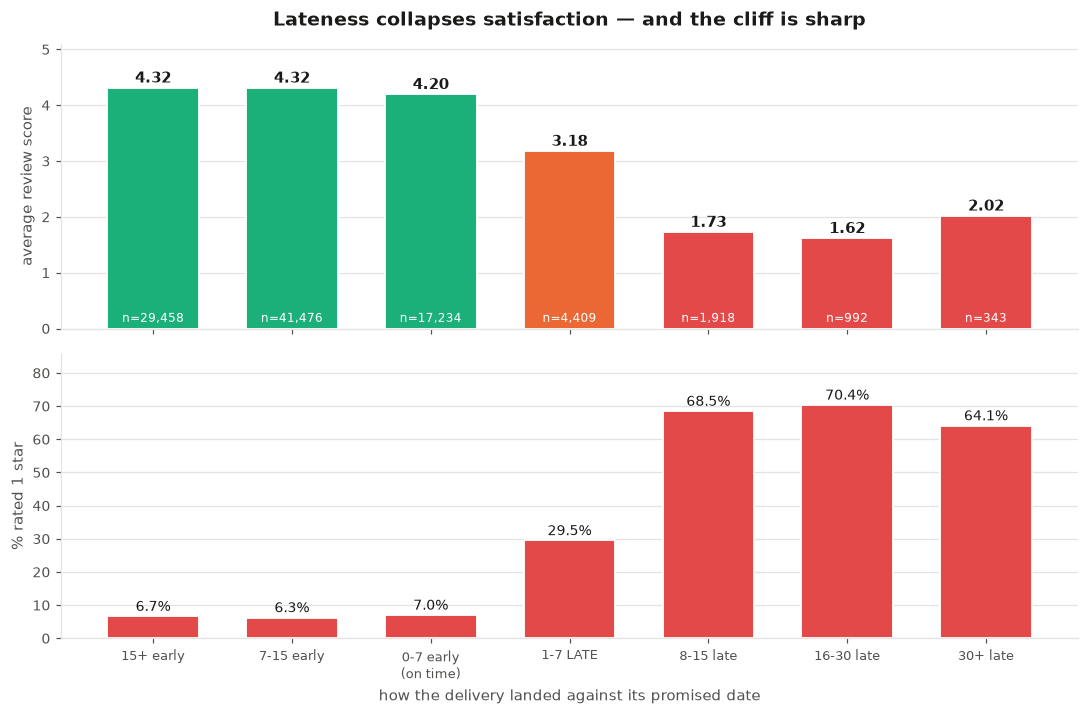

on time        -> 4.20 stars, 7.0% one-star
1-7 days late  -> 3.18 stars, 29.5% one-star
8-15 days late -> 1.73 stars, 68.5% one-star

Slipping just 1-7 days costs 1.02 stars
and multiplies one-star reviews by 4.2x.
Slipping 8-15 days multiplies them by 9.7x.


In [23]:
# One score per order first: 547 orders carry 2-3 reviews, and counting those
# twice would bias the result.
order_score = reviews.groupby("order_id").review_score.mean().rename("score")
dd = DELIVERED.merge(order_score, left_on="order_id", right_index=True, how="inner")

bins   = [-np.inf, -15, -7, 0, 7, 15, 30, np.inf]
labels = ["15+ early", "7-15 early", "0-7 early\n(on time)",
          "1-7 LATE", "8-15 late", "16-30 late", "30+ late"]
dd["bucket"] = pd.cut(dd.delay_days, bins=bins, labels=labels)

b = (dd.groupby("bucket", observed=True)
     .agg(orders=("order_id", "size"),
          avg_score=("score", "mean"),
          pct_1star=("score", lambda s: (s == 1).mean() * 100),
          pct_5star=("score", lambda s: (s == 5).mean() * 100))
     .reset_index())
display(b.round(3))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6.6), sharex=True,
                               gridspec_kw={"height_ratios": [1, 1]})
cols = [GOOD if v >= 4 else (ACCENT if v >= 3 else CRITICAL) for v in b.avg_score]
bars = ax1.bar(range(len(b)), b.avg_score, color=cols, width=0.66,
               edgecolor=SURFACE, linewidth=1.2)
for i, (sc, cnt) in enumerate(zip(b.avg_score, b.orders)):
    ax1.text(i, sc + 0.09, f"{sc:.2f}", ha="center", fontsize=9.5, fontweight="bold", color=INK)
    ax1.text(i, 0.12, f"n={cnt:,}", ha="center", fontsize=7.8, color=SURFACE)
ax1.set_ylim(0, 5.1); ax1.set_ylabel("average review score")
ax1.set_title("Lateness collapses satisfaction — and the cliff is sharp")
tidy(ax1)

bars2 = ax2.bar(range(len(b)), b.pct_1star, color=CRITICAL, width=0.66,
                edgecolor=SURFACE, linewidth=1.2)
for i, v in enumerate(b.pct_1star):
    ax2.text(i, v + 1.6, f"{v:.1f}%", ha="center", fontsize=9, color=INK)
ax2.set_ylabel("% rated 1 star")
ax2.set_ylim(0, b.pct_1star.max() * 1.22)
ax2.set_xticks(range(len(b))); ax2.set_xticklabels(b.bucket, fontsize=8.6)
ax2.set_xlabel("how the delivery landed against its promised date")
tidy(ax2)
plt.tight_layout()
save(fig, "F1_delivery_delay_vs_review_score")
plt.show()

ontime = b[b.bucket == "0-7 early\n(on time)"].iloc[0]
late17 = b[b.bucket == "1-7 LATE"].iloc[0]
late815 = b[b.bucket == "8-15 late"].iloc[0]
print(f"on time        -> {ontime.avg_score:.2f} stars, {ontime.pct_1star:.1f}% one-star")
print(f"1-7 days late  -> {late17.avg_score:.2f} stars, {late17.pct_1star:.1f}% one-star")
print(f"8-15 days late -> {late815.avg_score:.2f} stars, {late815.pct_1star:.1f}% one-star")
print(f"\nSlipping just 1-7 days costs {ontime.avg_score - late17.avg_score:.2f} stars")
print(f"and multiplies one-star reviews by {late17.pct_1star/ontime.pct_1star:.1f}x.")
print(f"Slipping 8-15 days multiplies them by {late815.pct_1star/ontime.pct_1star:.1f}x.")

**Reading it.** There is no gentle decline. Delivering *on time* scores 4.20.
Slipping even **1–7 days costs a full star** and roughly quadruples one-star
reviews. Slipping 8–15 days collapses the score to **1.73**, with **68.5%
one-star** — about ten times the on-time rate.

Two consequences that are easy to miss:

1. **Arriving very early buys almost nothing.** 15+ days early scores 4.318
   against 4.316 for 7–15 days early — statistically indistinguishable. All
   the padding in Section E1 produces no satisfaction upside; it only protects
   against the downside.
2. **The damage is front-loaded.** Most of the harm happens in the first week
   of lateness, so preventing a small slip matters far more than rescuing an
   already very late order.

**Caveat: correlation, not causation.** A late delivery may share a root cause
with a bad experience (an unreliable seller) rather than directly causing the
low score.

   saved -> reports/eda_charts/F2_review_score_by_category.png


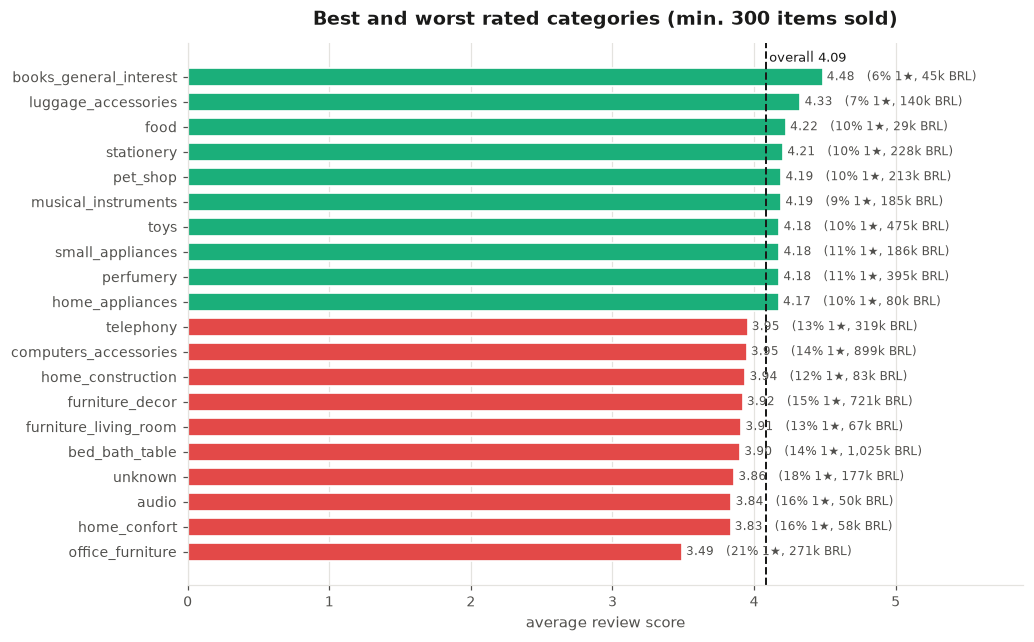

Revenue at risk — large categories rated below average:
                               items      revenue  avg_score  pct_1star
product_category_name_english                                          
watches_gifts                   5920 1,189,934.36       4.03      12.43
bed_bath_table                 10964 1,025,167.76       3.90      14.23
computers_accessories           7738   899,478.77       3.95      14.38
furniture_decor                 8215   721,186.90       3.92      14.53
housewares                      6871   622,487.22       4.07      11.57

combined revenue of below-average categories: 7.45M BRL (60% of rated revenue)


In [24]:
# Which categories disappoint? Needs a volume floor or tiny categories dominate.
cat_rev = (ELIG_ITEMS.merge(order_score, left_on="order_id", right_index=True, how="inner")
           .groupby("product_category_name_english")
           .agg(items=("price", "size"),
                revenue=("price", "sum"),
                avg_score=("score", "mean"),
                pct_1star=("score", lambda s: (s == 1).mean() * 100))
           .query("items >= 300"))

worst = cat_rev.nsmallest(10, "avg_score")
best  = cat_rev.nlargest(10, "avg_score")
show  = pd.concat([worst, best.iloc[::-1]])
overall = reviews.review_score.mean()

fig, ax = plt.subplots(figsize=(9.8, 6.4))
cols = [CRITICAL if v < overall else GOOD for v in show.avg_score]
bars = ax.barh(show.index, show.avg_score, color=cols, height=0.72,
               edgecolor=SURFACE, linewidth=1.1)
for bar, (c, r) in zip(bars, show.iterrows()):
    ax.text(bar.get_width() + 0.03, bar.get_y() + bar.get_height()/2,
            f"{r.avg_score:.2f}   ({r.pct_1star:.0f}% 1★, {r.revenue/1e3:,.0f}k BRL)",
            va="center", fontsize=8.1, color=INK_SOFT)
ax.axvline(overall, color=INK, linestyle="--", linewidth=1.3)
ax.text(overall + 0.02, len(show) - 0.4, f"overall {overall:.2f}", fontsize=8.6, color=INK)
ax.set_xlim(0, 5.9)
ax.set_xlabel("average review score")
ax.set_title("Best and worst rated categories (min. 300 items sold)")
tidy(ax, xgrid=True, ygrid=False)
save(fig, "F2_review_score_by_category")
plt.show()

risk = cat_rev[(cat_rev.avg_score < overall)].nlargest(5, "revenue")
print("Revenue at risk — large categories rated below average:")
print(risk[["items","revenue","avg_score","pct_1star"]].round(2).to_string())
print(f"\ncombined revenue of below-average categories: "
      f"{cat_rev[cat_rev.avg_score < overall].revenue.sum()/1e6:.2f}M BRL "
      f"({cat_rev[cat_rev.avg_score < overall].revenue.sum()/cat_rev.revenue.sum()*100:.0f}% of rated revenue)")

   saved -> reports/eda_charts/F3_review_score_by_order_status.png


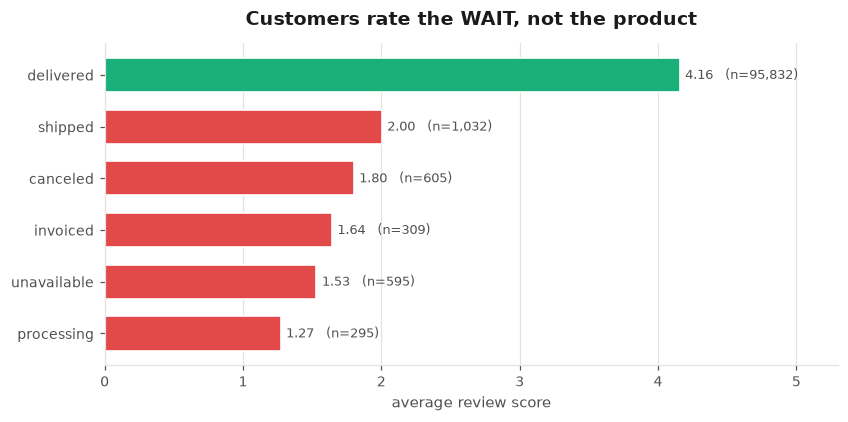

delivered orders: 4.16 stars
  processing   1.27  (+2.89 vs delivered)
  unavailable  1.53  (+2.63 vs delivered)
  invoiced     1.64  (+2.51 vs delivered)
  canceled     1.80  (+2.36 vs delivered)
  shipped      2.00  (+2.15 vs delivered)

An order still 'processing' or 'shipped' scores far below a delivered one.
These customers are reviewing the absence of their parcel. Fulfilment,
not product quality, is the dominant driver of satisfaction here.


In [25]:
# Does an order's fate (status) predict its rating? Non-delivery is the extreme
# case of lateness, so this extends F1 past the "never arrived" boundary.
st = (orders.merge(order_score, left_on="order_id", right_index=True, how="inner")
      .groupby("order_status")
      .agg(orders=("order_id", "size"), avg_score=("score", "mean"))
      .query("orders >= 100")
      .sort_values("avg_score"))

fig, ax = plt.subplots(figsize=(8.6, 3.8))
cols = [GOOD if v >= 4 else CRITICAL for v in st.avg_score]
bars = ax.barh(st.index, st.avg_score, color=cols, height=0.66,
               edgecolor=SURFACE, linewidth=1.1)
for bar, (s, r) in zip(bars, st.iterrows()):
    ax.text(bar.get_width() + 0.04, bar.get_y() + bar.get_height()/2,
            f"{r.avg_score:.2f}   (n={int(r.orders):,})", va="center",
            fontsize=8.6, color=INK_SOFT)
ax.set_xlim(0, 5.3)
ax.set_xlabel("average review score")
ax.set_title("Customers rate the WAIT, not the product")
tidy(ax, xgrid=True, ygrid=False)
save(fig, "F3_review_score_by_order_status")
plt.show()

deliv = st.loc["delivered", "avg_score"]
print(f"delivered orders: {deliv:.2f} stars")
for s in st.index:
    if s != "delivered":
        print(f"  {s:<12} {st.loc[s,'avg_score']:.2f}  ({deliv - st.loc[s,'avg_score']:+.2f} vs delivered)")
print("\nAn order still 'processing' or 'shipped' scores far below a delivered one.")
print("These customers are reviewing the absence of their parcel. Fulfilment,")
print("not product quality, is the dominant driver of satisfaction here.")

---
## G · Validation against MySQL

Everything above was computed in pandas from the cleaned CSVs. Phase 4
computed the same metrics in **MySQL**, a different engine reading a
separately loaded copy of the data.

Two independent implementations agreeing is evidence. One implementation is
just one implementation. This section connects to the live database and
compares them.

If MySQL is not running, the cell reports that and skips — it does not fail
the notebook, because the analysis above stands on its own.

In [26]:
MYSQL_AVAILABLE = False
try:
    import mysql.connector
    conn = mysql.connector.connect(host="127.0.0.1", user="root", database="retailpulse")
    MYSQL_AVAILABLE = True
    print("Connected to MySQL — running independent comparison.")
except Exception as e:                                   # noqa: BLE001
    print(f"MySQL not reachable ({type(e).__name__}). Skipping comparison.")
    print("Start it with:  brew services start mysql@8.4")

Connected to MySQL — running independent comparison.


In [27]:
if MYSQL_AVAILABLE:
    def sql_one(q):
        cur = conn.cursor()
        cur.execute(q)
        v = cur.fetchone()[0]
        cur.close()
        return float(v) if v is not None else None

    # Each pair: the pandas value computed above, and the SQL value, derived
    # independently. Nothing is copied between them.
    checks = [
        ("Total orders",
         float(len(orders)),
         sql_one("SELECT COUNT(*) FROM orders")),
        ("Distinct people (customer_unique_id)",
         float(orders.customer_unique_id.nunique()),
         sql_one("SELECT COUNT(DISTINCT customer_unique_id) FROM customers")),
        ("GMV all statuses",
         float(items.price.sum()),
         sql_one("SELECT SUM(price) FROM order_items")),
        ("Revenue eligible",
         float(ELIG_ITEMS.price.sum()),
         sql_one("SELECT SUM(oi.price) FROM order_items oi JOIN orders o ON o.order_id=oi.order_id WHERE o.revenue_eligible=1")),
        ("Freight charged",
         float(items.freight_value.sum()),
         sql_one("SELECT SUM(freight_value) FROM order_items")),
        ("Orders with items",
         float(items.order_id.nunique()),
         sql_one("SELECT COUNT(DISTINCT order_id) FROM order_items")),
        ("Eligible orders with items (AOV denominator)",
         float(len(ELIG[ELIG.has_items])),
         sql_one("SELECT COUNT(*) FROM vw_order_summary WHERE revenue_eligible=1 AND item_count>0")),
        ("Delivered orders",
         float(orders.is_delivered.sum()),
         sql_one("SELECT SUM(is_delivered) FROM orders")),
        ("Orders with a real delivery date",
         float(orders.delivery_measurable.sum()),
         sql_one("SELECT COUNT(*) FROM orders WHERE delivery_measurable=1")),
        ("Late deliveries",
         float(DELIVERED.is_late.sum()),
         sql_one("SELECT SUM(is_late) FROM orders WHERE delivery_measurable=1")),
        ("Avg delivery days",
         float(DELIVERED.delivery_days.mean()),
         sql_one("SELECT AVG(delivery_days) FROM orders WHERE delivery_measurable=1")),
        ("Avg review score (review grain)",
         float(reviews.review_score.mean()),
         sql_one("SELECT AVG(review_score) FROM order_reviews")),
        ("Stable-window eligible revenue",
         float(monthly.revenue.sum()),
         sql_one("SELECT SUM(oi.price) FROM order_items oi JOIN orders o ON o.order_id=oi.order_id WHERE o.revenue_eligible=1 AND o.in_stable_window=1")),
        ("SP state revenue",
         float(state_rev.loc["SP", "revenue"]),
         sql_one("SELECT SUM(oi.price) FROM order_items oi JOIN orders o ON o.order_id=oi.order_id JOIN customers c ON c.customer_id=o.customer_id WHERE o.revenue_eligible=1 AND c.customer_state='SP'")),
        ("health_beauty category revenue",
         float(cat.loc["health_beauty", "revenue"]),
         sql_one("SELECT SUM(oi.price) FROM order_items oi JOIN orders o ON o.order_id=oi.order_id JOIN products p ON p.product_id=oi.product_id WHERE o.revenue_eligible=1 AND p.product_category_name_english='health_beauty'")),
    ]

    rows = []
    for name, py, sq in checks:
        diff = abs(py - sq) if (py is not None and sq is not None) else None
        rows.append({"metric": name, "pandas": py, "mysql": sq,
                     "abs_diff": diff,
                     "result": "PASS" if (diff is not None and diff < 0.01) else "FAIL"})
    comp = pd.DataFrame(rows)
    display(comp.round(4))

    n_fail = int((comp.result == "FAIL").sum())
    print(f"\nChecks: {len(comp)}   PASS: {len(comp)-n_fail}   FAIL: {n_fail}")
    if n_fail:
        print("\nMISMATCHES — investigate; never edit a verified reference to force agreement:")
        display(comp[comp.result == "FAIL"])
    else:
        print("Every metric agrees between pandas and MySQL to within 0.01.")
    conn.close()

,metric,pandas,mysql,abs_diff,result
0,Total orders,"99,441.00","99,441.00",0.00,PASS
1,Distinct people (customer_unique_id),"96,096.00","96,096.00",0.00,PASS
2,GMV all statuses,"13,591,643.70","13,591,643.70",0.00,PASS
3,Revenue eligible,"13,494,400.74","13,494,400.74",0.00,PASS
4,Freight charged,"2,251,909.54","2,251,909.54",0.00,PASS
5,Orders with items,"98,666.00","98,666.00",0.00,PASS
6,Eligible orders with items (AOV denominator),"98,199.00","98,199.00",0.00,PASS
7,Delivered orders,"96,478.00","96,478.00",0.00,PASS
8,Orders with a real delivery date,"96,476.00","96,476.00",0.00,PASS
9,Late deliveries,"7,827.00","7,827.00",0.00,PASS



Checks: 15   PASS: 15   FAIL: 0
Every metric agrees between pandas and MySQL to within 0.01.


---
## H · Summary

In [28]:
print("=" * 78)
print("CHARTS PRODUCED")
print("=" * 78)
for i, n in enumerate(SAVED, 1):
    print(f"  {i:>2}. {n}.png")
print(f"\nTotal: {len(SAVED)} charts saved to reports/eda_charts/")

CHARTS PRODUCED
   1. A1_revenue_trend_and_mom_growth.png
   2. A2_growth_decomposition_indexed.png
   3. A3_revenue_by_state_pareto.png
   4. B1_customer_value_lorenz.png
   5. B2_rfm_segments_customers_vs_revenue.png
   6. B3_cohort_retention_heatmap.png
   7. C1_category_revenue_and_concentration.png
   8. C2_category_growth_vs_decline.png
   9. D1_seller_revenue_concentration.png
  10. D2_seller_scorecard_late_vs_review.png
  11. E1_promised_vs_actual_delivery.png
  12. E2_delivery_by_state.png
  13. F1_delivery_delay_vs_review_score.png
  14. F2_review_score_by_category.png
  15. F3_review_score_by_order_status.png

Total: 15 charts saved to reports/eda_charts/


In [29]:
print("=" * 78)
print("HEADLINE FINDINGS (all computed above, none asserted without a cell)")
print("=" * 78)

ontime_row = b[b.bucket == "0-7 early\n(on time)"].iloc[0]
late_row   = b[b.bucket == "8-15 late"].iloc[0]
f_, l_     = by_month.iloc[0], by_month.iloc[-1]

findings = [
    ("Growth is volume, not basket size",
     f"orders {monthly.orders.iloc[0]:,.0f} -> {monthly.orders.iloc[-1]:,.0f} "
     f"({monthly.orders.iloc[-1]/monthly.orders.iloc[0]-1:+.0%}), "
     f"AOV {monthly.aov.iloc[0]:.2f} -> {monthly.aov.iloc[-1]:.2f} "
     f"({monthly.aov.iloc[-1]/monthly.aov.iloc[0]-1:+.1%})"),
    ("2018 is a plateau, not continued growth",
     f"mean MoM growth 2017 {monthly[monthly.order_month<'2018-01'].mom_pct.mean():+.1f}% "
     f"vs 2018 {monthly[monthly.order_month>='2018-01'].mom_pct.mean():+.1f}%"),
    ("Geography is the real concentration risk",
     f"top 3 of 27 states = {state_rev.head(3).pct.sum():.1f}% of revenue; "
     f"top 10 of 74 categories = only {cat.head(10).pct.sum():.1f}%"),
    ("High-value customers exist, but they are not loyal — they bought once",
     f"top 10% hold {cum_rev.iloc[int(N_CUSTOMERS*0.1)-1]:.0f}% of revenue, yet "
     f"{ranked.head(int(len(ranked)*0.01)).orders.eq(1).mean()*100:.0f}% of the top 1% "
     f"placed exactly one order"),
    ("Champions are not the opportunity; Potential Loyalists are",
     f"Champions {seg.loc['Champions','pct_revenue']:.1f}% of revenue vs "
     f"Potential Loyalists {seg.loc['Potential Loyalists','pct_revenue']:.1f}%"),
    ("Retention is effectively zero",
     f"every cohort cell < 1.5%; mean ever-returned across 2017 cohorts "
     f"{ever[ever.index<'2018-01'].mean():.2f}%"),
    ("Lateness destroys satisfaction, with a sharp cliff",
     f"on time {ontime_row.avg_score:.2f} stars / {ontime_row.pct_1star:.1f}% 1-star -> "
     f"8-15 days late {late_row.avg_score:.2f} stars / {late_row.pct_1star:.1f}% 1-star"),
    ("Arriving very early buys nothing",
     f"15+ days early {b.iloc[0].avg_score:.3f} vs 7-15 days early {b.iloc[1].avg_score:.3f}"),
    ("Delivery promises are padded but converging",
     f"{f_.order_month}: promised {f_.promised:.0f}d / actual {f_.actual:.0f}d -> "
     f"{l_.order_month}: promised {l_.promised:.0f}d / actual {l_.actual:.0f}d"),
    ("Delivery quality varies enormously by state",
     f"{state.index[0]} {state.avg_days.iloc[0]:.1f}d vs "
     f"{state.index[-1]} {state.avg_days.iloc[-1]:.1f}d "
     f"({state.avg_days.iloc[-1]/state.avg_days.iloc[0]:.1f}x)"),
    ("Seller risk is tier-wide, not single-seller",
     f"largest seller {sell.pct_revenue.iloc[0]:.2f}%, but top 10% of sellers "
     f"{cum.iloc[int(len(sell)*0.1)-1]:.0f}%"),
    ("Customers rate the wait, not the product",
     f"delivered {st.loc['delivered','avg_score']:.2f} stars vs "
     f"processing {st.loc['processing','avg_score']:.2f} stars"),
]
for i, (title, detail) in enumerate(findings, 1):
    print(f"\n{i:>2}. {title}")
    print(f"    {detail}")

print("\n" + "=" * 78)
print("Every figure above was produced by a cell in this notebook.")
print("Correlations are labelled as correlations. No causal claim is made.")
print("NEXT: Phase 6 — Power BI dashboards built on the Phase 4 SQL views.")

HEADLINE FINDINGS (all computed above, none asserted without a cell)

 1. Growth is volume, not basket size
    orders 787 -> 6,421 (+716%), AOV 152.60 -> 132.20 (-13.4%)

 2. 2018 is a plateau, not continued growth
    mean MoM growth 2017 +22.7% vs 2018 +2.5%

 3. Geography is the real concentration risk
    top 3 of 27 states = 63.4% of revenue; top 10 of 74 categories = only 62.4%

 4. High-value customers exist, but they are not loyal — they bought once
    top 10% hold 41% of revenue, yet 93% of the top 1% placed exactly one order

 5. Champions are not the opportunity; Potential Loyalists are
    Champions 2.4% of revenue vs Potential Loyalists 33.9%

 6. Retention is effectively zero
    every cohort cell < 1.5%; mean ever-returned across 2017 cohorts 3.07%

 7. Lateness destroys satisfaction, with a sharp cliff
    on time 4.20 stars / 7.0% 1-star -> 8-15 days late 1.73 stars / 68.5% 1-star

 8. Arriving very early buys nothing
    15+ days early 4.318 vs 7-15 days early 4.316